# PPG feature extraction

Turn each cleaned five-second window into pulse measurements.
Build on the team's feature calculations and reuse the saved SBP/DBP labels.

## 1. Load the cleaned data

- Run `preprocess.ipynb` first.
- Read the cleaned PPG, labels, source IDs, and power scores from its `.npz` file.
- Read PPG from a temporary disk file to avoid loading it all into RAM.
- Keep the saved labels unchanged so both notebooks use the same answers.

In [2]:
from pathlib import Path
import json
import tempfile
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

data_dir = Path('../data')
results_dir = Path('../results')
graphs_dir = results_dir / 'graphs'
graphs_dir.mkdir(parents=True, exist_ok=True)
settings = json.loads((results_dir / 'data_pipeline_stats.json').read_text())
FS = settings['sampling_rate_hz']
WINDOW_SAMPLES = settings['window_samples']
MIN_PEAK_DISTANCE = settings['min_peak_distance_samples']
MIN_COMPLETE_BEATS = 2

# Open only the large PPG array from disk; the other arrays are small.
temp_dir = tempfile.TemporaryDirectory(prefix='ppg_features_', dir=data_dir)
with ZipFile(data_dir / 'processed_dataset.npz') as archive:
    archive.extract('X.npy', temp_dir.name)
X = np.load(Path(temp_dir.name) / 'X.npy', mmap_mode='r')
with np.load(data_dir / 'processed_dataset.npz') as saved:
    labels = saved['y']
    source = pd.DataFrame({
        'file': saved['file_names'][saved['file_index']],
        'record_index': saved['record_index'],
        'start_sample': saved['start_sample'],
        'inband_power_ratio': saved['inband_power_ratio'],
        'sbp': labels[:, 0],
        'dbp': labels[:, 1],
    })
assert X.shape == (len(source), WINDOW_SAMPLES)
assert len(source) == settings['accepted_windows']
assert np.isfinite(labels).all()
print(f'Loaded {len(source):,} cleaned windows; {WINDOW_SAMPLES} readings each.')

Loaded 527,472 cleaned windows; 625 readings each.


## 2. Find the pulses

- A **peak** is the top of a pulse. A **foot** is the low point between peaks.
- Keep the original peak rule: a peak must stand out by 0.3 times the window's standard deviation. This helps ignore small bumps; it is a starting rule.
- Use preprocessing's minimum peak spacing (about a third of a second) to avoid counting nearby bumps as separate beats.
- A complete pulse needs a foot, a peak, and the next foot. Edge pulses may be incomplete.
- Require two complete pulses so the measurements describe more than one pulse.

In [3]:
def find_beats(ppg):
    peaks, _ = find_peaks(ppg, distance=MIN_PEAK_DISTANCE,
                          prominence=0.3 * np.std(ppg))
    beats = []
    for k in range(1, len(peaks) - 1):
        foot = peaks[k - 1] + np.argmin(ppg[peaks[k - 1]:peaks[k]])
        next_foot = peaks[k] + np.argmin(ppg[peaks[k]:peaks[k + 1]])
        if foot < peaks[k] < next_foot:
            beats.append((foot, peaks[k], next_foot))
    return peaks, beats

## 3. Measure each window

Keep the original pulse measurements and average them across complete pulses.

| Measurement | What it means |
|---|---|
| `heart_rate_bpm` | Beats per minute, estimated from peak spacing |
| `beat_interval_std_ms` | How much beat spacing changes in these five seconds |
| `pulse_height` | Height from the foot to the peak |
| `rise_time_s`, `fall_time_s` | Seconds spent rising and falling |
| `rise_fall_ratio` | Rise time divided by fall time |
| `pulse_width_s` | Time above half the pulse height |
| `max_upslope` | Steepest upward change per second |
| `ppg_std`, `ppg_min`, `ppg_max`, `ppg_range` | Spread, lowest value, highest value, and their difference |
| `ppg_skewness`, `ppg_kurtosis` | How uneven or extreme the readings are |

- Beat-spacing variation describes this short window, not a clinical HRV measurement.
- Leave out the original raw-signal average because this file contains cleaned PPG.
- Do not filter again or add new blood-pressure limits. Preprocessing already handled cleaning and labels.

In [4]:
def extract_ppg_features(ppg_window):
    ppg_window = np.asarray(ppg_window, dtype=float)
    peaks, beats = find_beats(ppg_window)
    if len(beats) < MIN_COMPLETE_BEATS:
        return None

    rise, fall, height, width, upslope = [], [], [], [], []
    for foot, peak, next_foot in beats:
        h = ppg_window[peak] - ppg_window[foot]
        rise.append((peak - foot) / FS)
        fall.append((next_foot - peak) / FS)
        height.append(h)
        # Count the time spent above half the pulse height.
        pulse = ppg_window[foot:next_foot + 1]
        width.append(np.sum(pulse >= ppg_window[foot] + 0.5 * h) / FS)
        upslope.append(np.max(np.diff(ppg_window[foot:peak + 1])) * FS)

    intervals = np.diff(peaks) / FS
    rise, fall = np.array(rise), np.array(fall)
    spread = np.std(ppg_window)
    # Share the work for the original skewness and kurtosis formulas.
    standardized = (ppg_window - np.mean(ppg_window)) / spread
    return {
        'heart_rate_bpm': 60 / np.mean(intervals),
        'beat_interval_std_ms': np.std(intervals) * 1000,
        'pulse_height': np.mean(height),
        'rise_time_s': np.mean(rise),
        'fall_time_s': np.mean(fall),
        'rise_fall_ratio': np.mean(rise / fall),
        'pulse_width_s': np.mean(width),
        'max_upslope': np.mean(upslope),
        'ppg_std': spread,
        'ppg_min': np.min(ppg_window),
        'ppg_max': np.max(ppg_window),
        'ppg_range': np.ptp(ppg_window),
        'ppg_skewness': np.mean(standardized ** 3),
        'ppg_kurtosis': np.mean(standardized ** 4) - 3,
        'n_beats': len(beats),
    }

feature_columns = [
    'heart_rate_bpm', 'beat_interval_std_ms', 'pulse_height', 'rise_time_s',
    'fall_time_s', 'rise_fall_ratio', 'pulse_width_s', 'max_upslope',
    'ppg_std', 'ppg_min', 'ppg_max', 'ppg_range', 'ppg_skewness', 'ppg_kurtosis',
]

## 4. Build the feature table

- Measure each cleaned window once.
- Skip windows with fewer than two complete pulses or an undefined measurement. Count each reason.
- Copy labels and source IDs using the same row numbers so they stay matched.
- Keep beat counts and power scores as extra information, separate from the 14 features.

In [5]:
# Preallocate the measurements instead of keeping a large list of dictionaries.
measurements = feature_columns + ['n_beats']
values = np.full((len(source), len(measurements)), np.nan)
skipped = {'too_few_complete_beats': 0, 'undefined_features': 0}
for row_index, window in enumerate(X):
    features = extract_ppg_features(window)
    if features is None:
        skipped['too_few_complete_beats'] += 1
        continue
    row = [features[name] for name in measurements]
    if not np.isfinite(row).all():
        skipped['undefined_features'] += 1
        continue
    values[row_index] = row
    if (row_index + 1) % 100000 == 0:
        print(f'Checked {row_index + 1:,} windows')

valid = np.isfinite(values).all(axis=1)
kept_indices = np.flatnonzero(valid)
df = source.loc[valid].reset_index(drop=True).copy()
df[measurements] = values[valid]
df['n_beats'] = df['n_beats'].astype(int)
assert len(df) > 0
assert len(df) + sum(skipped.values()) == len(source)
assert np.isfinite(df[measurements + ['sbp', 'dbp']]).all().all()
assert not df.duplicated(['file', 'record_index', 'start_sample']).any()
np.testing.assert_array_equal(df[['sbp', 'dbp']].to_numpy(), labels[valid])
print(f'Kept {len(df):,} of {len(source):,} windows.')
print('Skipped:', skipped)
print(f'Features per window: {len(feature_columns)}')
counts = pd.DataFrame({
    'input_windows': source.groupby('file').size(),
    'kept_windows': df.groupby('file').size(),
}).fillna(0).astype(int)
counts['skipped_windows'] = counts['input_windows'] - counts['kept_windows']
counts

Checked 100,000 windows


Checked 200,000 windows


Checked 300,000 windows


Checked 400,000 windows


Checked 500,000 windows


Kept 527,467 of 527,472 windows.
Skipped: {'too_few_complete_beats': 5, 'undefined_features': 0}
Features per window: 14


,input_windows,kept_windows,skipped_windows
file,,,
Part_1.mat,130924,130922,2
Part_2.mat,150976,150975,1
Part_3.mat,112068,112068,0
Part_4.mat,133504,133502,2


## 5. See a measured pulse

- Show the first usable window, with its original recording and starting time.
- Red markers show peaks. Green markers show the feet of complete pulses.
- The shaded pulse shows the part used to measure height and rise/fall time.

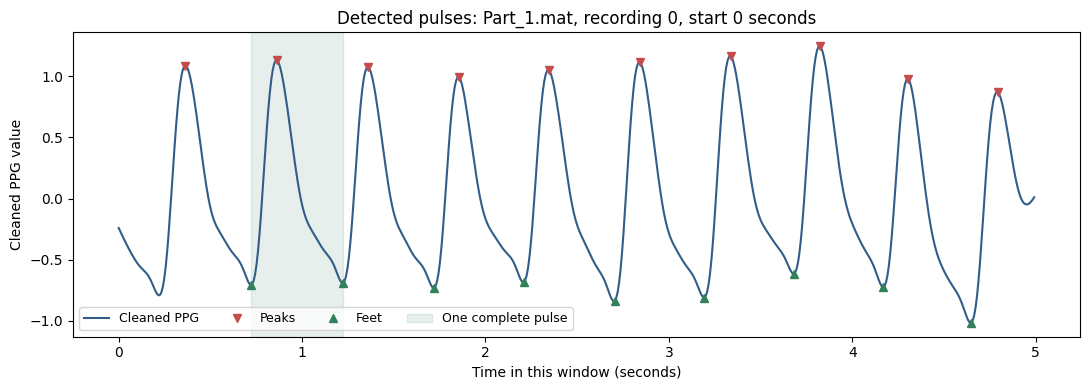

,heart_rate_bpm,beat_interval_std_ms,pulse_height,rise_time_s,fall_time_s,rise_fall_ratio,pulse_width_s,max_upslope,ppg_std,ppg_min,ppg_max,ppg_range,ppg_skewness,ppg_kurtosis
0,121.841,6.652,1.817,0.139,0.352,0.395,0.172,22.567,0.604,-1.015,1.244,2.26,0.516,-1.049


In [6]:
example_index = kept_indices[0]
example = np.asarray(X[example_index], dtype=float)
peaks, beats = find_beats(example)
feet = sorted({b[0] for b in beats} | {b[2] for b in beats})
t = np.arange(WINDOW_SAMPLES) / FS
info = source.iloc[example_index]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, example, color='#325d88', label='Cleaned PPG')
ax.plot(t[peaks], example[peaks], 'v', color='#c44c4c', label='Peaks')
ax.plot(t[feet], example[feet], '^', color='#32815b', label='Feet')
foot, peak, next_foot = beats[0]
ax.axvspan(t[foot], t[next_foot], alpha=0.12, color='#32815b', label='One complete pulse')
ax.set(title=f"Detected pulses: {info['file']}, recording {info['record_index']}, "
             f"start {info['start_sample'] / FS:g} seconds",
       xlabel='Time in this window (seconds)', ylabel='Cleaned PPG value')
ax.legend(ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(graphs_dir / 'feature_beats.png', dpi=150)
plt.show()
plt.close(fig)
df.loc[[0], feature_columns].round(3)

## 6. See how the measurements vary

- Each bar counts windows with similar measurements.
- Taller bars mean more windows have that value.
- These are measurements from detected pulses, not confirmed true heart rates or pulse shapes.

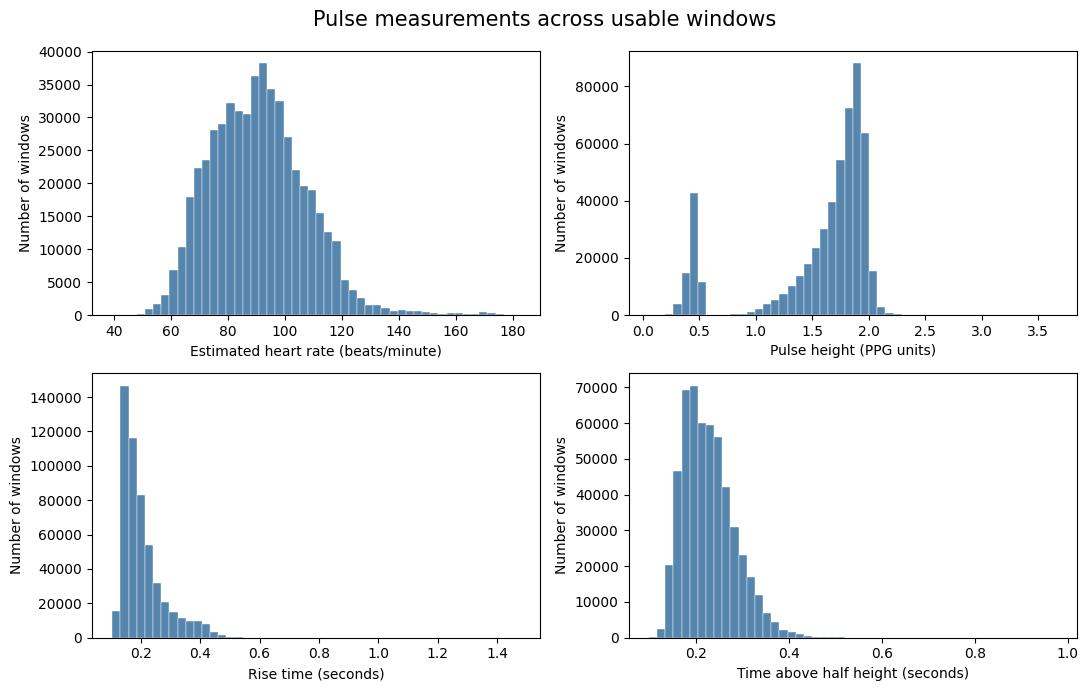

,heart_rate_bpm,beat_interval_std_ms,pulse_height,rise_time_s,fall_time_s,rise_fall_ratio,pulse_width_s,max_upslope,ppg_std,ppg_min,ppg_max,ppg_range,ppg_skewness,ppg_kurtosis
count,527467.000,527467.000,527467.000,527467.000,527467.000,527467.000,527467.000,527467.000,527467.000,527467.000,527467.000,527467.000,527467.000,527467.000
mean,90.716,32.195,1.565,0.206,0.480,0.498,0.228,16.488,0.528,-0.804,1.208,2.012,0.613,-0.697
std,16.943,47.731,0.497,0.072,0.127,0.344,0.055,5.725,0.166,0.285,0.408,0.648,0.281,0.449
min,39.336,0.000,0.054,0.105,0.105,0.128,0.100,0.765,0.018,-3.687,0.061,0.124,-2.865,-1.570
25%,78.288,6.110,1.484,0.154,0.403,0.317,0.186,14.442,0.512,-0.965,1.124,1.966,0.447,-0.998
50%,90.180,10.583,1.763,0.183,0.481,0.377,0.221,17.900,0.584,-0.850,1.299,2.171,0.620,-0.787
75%,101.156,32.796,1.892,0.230,0.563,0.497,0.261,20.512,0.630,-0.723,1.441,2.370,0.787,-0.510
max,182.609,1044.959,3.663,1.476,1.156,4.232,0.976,41.193,1.215,-0.062,4.379,5.940,2.793,11.755


In [7]:
plot_features = {
    'heart_rate_bpm': 'Estimated heart rate (beats/minute)',
    'pulse_height': 'Pulse height (PPG units)',
    'rise_time_s': 'Rise time (seconds)',
    'pulse_width_s': 'Time above half height (seconds)',
}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (name, title) in zip(axes.flat, plot_features.items()):
    ax.hist(df[name], bins=50, color='#5686ad', edgecolor='white', linewidth=0.3)
    ax.set(xlabel=title, ylabel='Number of windows')
    ax.ticklabel_format(axis='y', style='plain')
fig.suptitle('Pulse measurements across usable windows', fontsize=15)
fig.tight_layout()
fig.savefig(graphs_dir / 'feature_distributions.png', dpi=150)
plt.show()
plt.close(fig)
df[feature_columns].describe().round(3)

## 7. Compare features with blood pressure

- Compare each feature with the saved SBP and DBP labels using correlation.
- A positive number means they tend to rise together. A negative number means they tend to move in opposite directions.
- Numbers near zero mean a weak straight-line relationship.
- This describes these windows. It does not test a model or show that a feature causes blood pressure to change.
- Windows can share recordings. Keep each recording together when splitting data later; these comparisons do not use patient IDs.

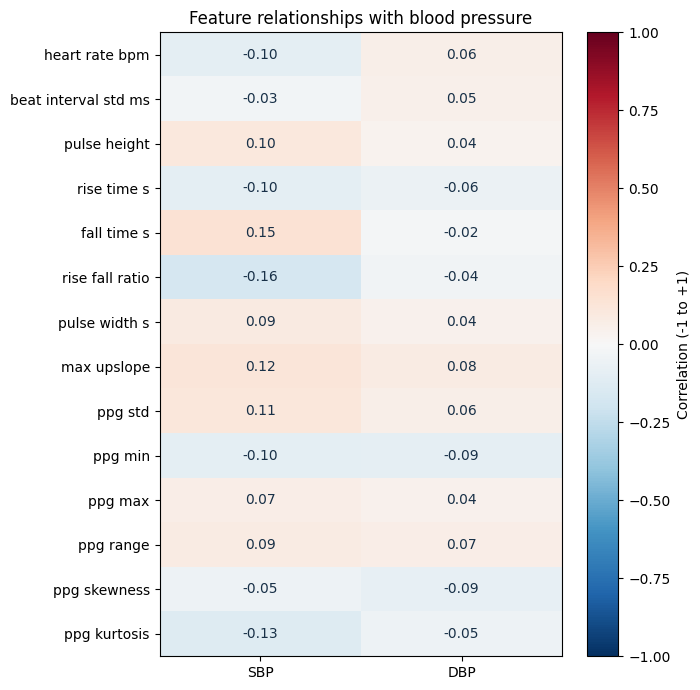

Strongest SBP relationship: rise_fall_ratio (-0.164)
Strongest DBP relationship: ppg_min (-0.092)


,sbp,dbp
heart_rate_bpm,-0.099,0.060
beat_interval_std_ms,-0.025,0.048
pulse_height,0.102,0.035
rise_time_s,-0.098,-0.060
fall_time_s,0.145,-0.018
rise_fall_ratio,-0.164,-0.038
pulse_width_s,0.089,0.043
max_upslope,0.122,0.083
ppg_std,0.112,0.057
ppg_min,-0.098,-0.092


In [8]:
corr = df[feature_columns + ['sbp', 'dbp']].corr()[['sbp', 'dbp']].loc[feature_columns]
fig, ax = plt.subplots(figsize=(7, 7))
image = ax.imshow(corr.to_numpy(), cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks([0, 1], ['SBP', 'DBP'])
ax.set_yticks(range(len(corr)), [name.replace('_', ' ') for name in corr.index])
for row in range(len(corr)):
    for col in range(2):
        value = corr.iloc[row, col]
        ax.text(col, row, f'{value:.2f}', ha='center', va='center',
                color='white' if abs(value) > 0.5 else '#183047')
ax.set_title('Feature relationships with blood pressure')
fig.colorbar(image, ax=ax, label='Correlation (-1 to +1)')
fig.tight_layout()
fig.savefig(graphs_dir / 'feature_correlations.png', dpi=150)
plt.show()
plt.close(fig)
for label in ['sbp', 'dbp']:
    strongest = corr[label].abs().idxmax()
    print(f'Strongest {label.upper()} relationship: {strongest} ({corr.loc[strongest, label]:.3f})')
corr.round(3)

## 8. Save and check the dataset

- Save `data/ppg_features.csv`: one row per usable five-second window.
- The 14 columns in `feature_columns` are the model inputs. SBP and DBP are the answers.
- File, recording number, and starting row identify the source. They are not prediction inputs.
- Read back the CSV in small batches to check its rows, measurements, labels, and source IDs.

In [9]:
output_file = data_dir / 'ppg_features.csv'
df.to_csv(output_file, index=False)

# Check the saved file without loading a second full copy into RAM.
saved_rows = 0
for chunk in pd.read_csv(output_file, chunksize=25000):
    expected = df.iloc[saved_rows:saved_rows + len(chunk)]
    assert chunk.columns.tolist() == df.columns.tolist()
    assert chunk['file'].tolist() == expected['file'].tolist()
    np.testing.assert_array_equal(chunk[['record_index', 'start_sample', 'n_beats']],
                                  expected[['record_index', 'start_sample', 'n_beats']])
    numeric = feature_columns + ['sbp', 'dbp', 'inband_power_ratio']
    np.testing.assert_allclose(chunk[numeric], expected[numeric], rtol=1e-6, atol=1e-10)
    saved_rows += len(chunk)
assert saved_rows == len(df)
print(f'Saved and checked {saved_rows:,} rows in {output_file}.')
print('Labels and source IDs match the cleaned dataset. All features are finite.')

# Close the disk-backed array before removing its temporary file on Windows.
X._mmap.close()
temp_dir.cleanup()

Saved and checked 527,467 rows in ..\data\ppg_features.csv.
Labels and source IDs match the cleaned dataset. All features are finite.
